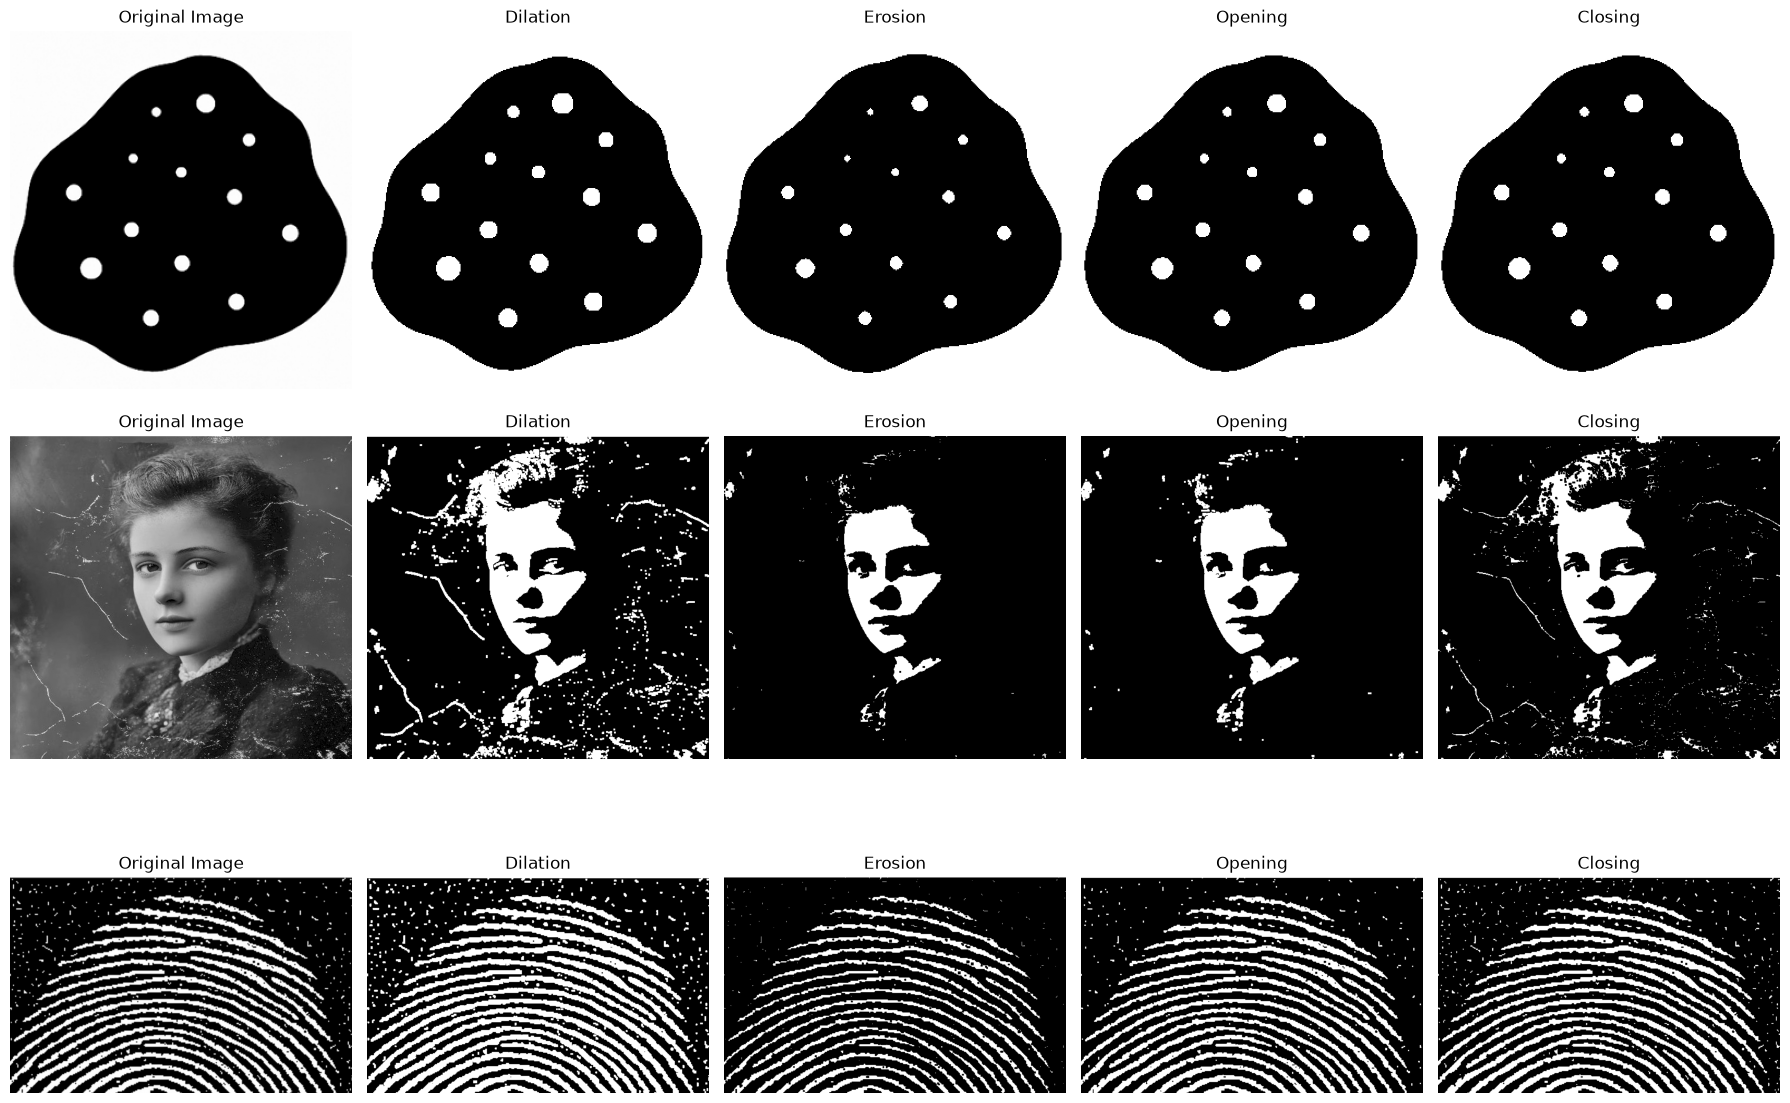

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
image_names = ["img_01.png", "img_02.png", "img_03.png"]

# Define structuring element
kernel = np.ones((3, 3), np.uint8)

# Create figure for displaying results
plt.figure(figsize=(18, 12))
for i, image_name in enumerate(image_names):

    # Read image in grayscale
    image = cv2.imread(image_name, 0)
    if image is None:
        print("Image not found:", image_name)
        continue

    # Convert image into binary format
    _, binary = cv2.threshold(
        image, 127, 255, cv2.THRESH_BINARY
    )

    # Apply dilation
    dilation = cv2.dilate(binary, kernel, iterations=1)
    # Apply erosion
    erosion = cv2.erode(binary, kernel, iterations=1)
    # Apply opening
    opening = cv2.morphologyEx(
        binary, cv2.MORPH_OPEN, kernel
    )
    # Apply closing
    closing = cv2.morphologyEx(
        binary, cv2.MORPH_CLOSE, kernel
    )

    # Store all results
    results = [
        image,
        dilation,
        erosion,
        opening,
        closing
    ]
    titles = [
        "Original Image",
        "Dilation",
        "Erosion",
        "Opening",
        "Closing"
    ]

    # Display five results for each image
    for j in range(5):

        plt.subplot(3, 5, i * 5 + j + 1)

        plt.imshow(results[j], cmap="gray")
        plt.title(titles[j])
        plt.axis("off")
plt.tight_layout()
plt.show()
